# Exploratory Data Analysis

Features and overall metrics only. Outcomes are not compared across customer segments until the analysis plan is committed.

In [1]:
import pandas as pd

df = pd.read_csv("../data/hillstrom.csv")
df.head(10)

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0
5,6,2) $100 - $200,134.83,0,1,Surburban,0,Phone,Womens E-Mail,1,0,0.0
6,9,3) $200 - $350,280.20,1,0,Surburban,1,Phone,Womens E-Mail,0,0,0.0
7,9,1) $0 - $100,46.42,0,1,Urban,0,Phone,Womens E-Mail,0,0,0.0
8,9,5) $500 - $750,675.07,1,1,Rural,1,Phone,Mens E-Mail,0,0,0.0
9,10,1) $0 - $100,32.84,0,1,Urban,1,Web,Womens E-Mail,0,0,0.0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  str    
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  str    
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  str    
 8   segment          64000 non-null  str    
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), str(4)
memory usage: 5.9 MB


In [3]:
df.describe()

,recency,history,mens,womens,newbie,visit,conversion,spend
count,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000
mean,5.763734,242.085656,0.551031,0.549719,0.502250,0.146781,0.009031,1.050908
std,3.507592,256.158608,0.497393,0.497526,0.499999,0.353890,0.094604,15.036448
min,1.000000,29.990000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,64.660000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,6.000000,158.110000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
75%,9.000000,325.657500,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
max,12.000000,3345.930000,1.000000,1.000000,1.000000,1.000000,1.000000,499.000000


## Column overview

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

BLUE = "#2a78d6"
INK = "#0b0b0b"
GRID = "#e4e3df"
FIGURES = Path("../reports/figures")
FIGURES.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "text.color": INK,
    "text.parse_math": False,
})


def count_table(column):
    counts = df[column].value_counts().sort_index()
    return pd.DataFrame({"customers": counts, "share": (counts / len(df)).round(3)})


def box_plot(ax, values):
    ax.boxplot(
        values,
        orientation="horizontal",
        widths=0.5,
        patch_artist=True,
        boxprops={"facecolor": "#b7d3f6", "edgecolor": BLUE},
        medianprops={"color": "#0d366b", "linewidth": 2},
        whiskerprops={"color": BLUE},
        capprops={"color": BLUE},
        flierprops={"marker": "o", "markersize": 3, "markerfacecolor": BLUE, "markeredgecolor": "none", "alpha": 0.3},
    )
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)


def save_and_show(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

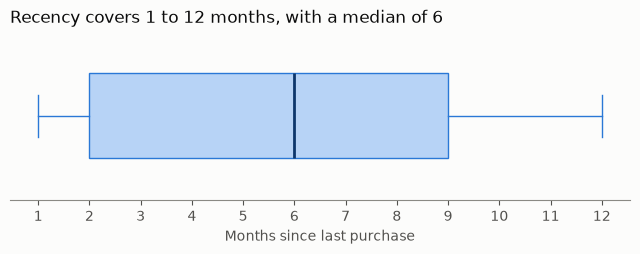

In [5]:
fig, ax = plt.subplots(figsize=(8, 2.2))
box_plot(ax, df["recency"])
ax.set_xticks(range(1, 13))
ax.set_xlabel("Months since last purchase")
ax.set_title(f"Recency covers 1 to 12 months, with a median of {df['recency'].median():.0f}")
save_and_show(fig, "recency")

,count,min,max
history_segment,,,
1) $0 - $100,22970,29.99,99.99
2) $100 - $200,14254,100.00,199.98
3) $200 - $350,12289,200.00,349.96
4) $350 - $500,6409,350.01,499.95
5) $500 - $750,4911,500.00,749.79
"6) $750 - $1,000",1859,750.01,999.75
"7) $1,000 +",1308,1000.15,3345.93


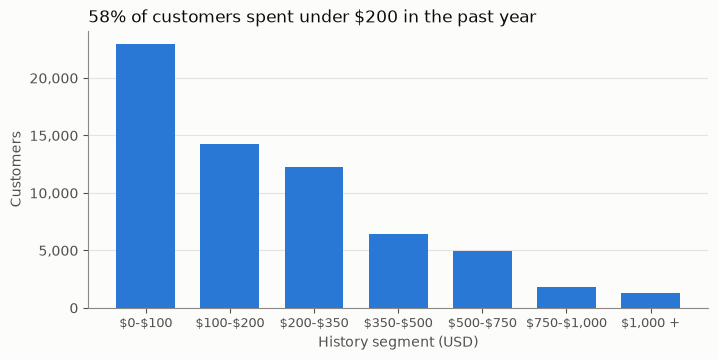

In [6]:
segments = df.groupby("history_segment")["history"].agg(["count", "min", "max"])
display(segments)

labels = segments.index.str.split(") ", regex=False).str[1].str.replace(" - ", "-", regex=False)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(labels, segments["count"], color=BLUE, width=0.7)
ax.tick_params(axis="x", labelsize=9)
ax.set_xlabel("History segment (USD)")
ax.set_ylabel("Customers")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title(f"{segments['count'].iloc[:2].sum() / len(df):.0%} of customers spent under $200 in the past year")
save_and_show(fig, "history_segment")

skewness: 2.42 raw, -0.01 after log transform
customers at the minimum of $29.99: 12.4%


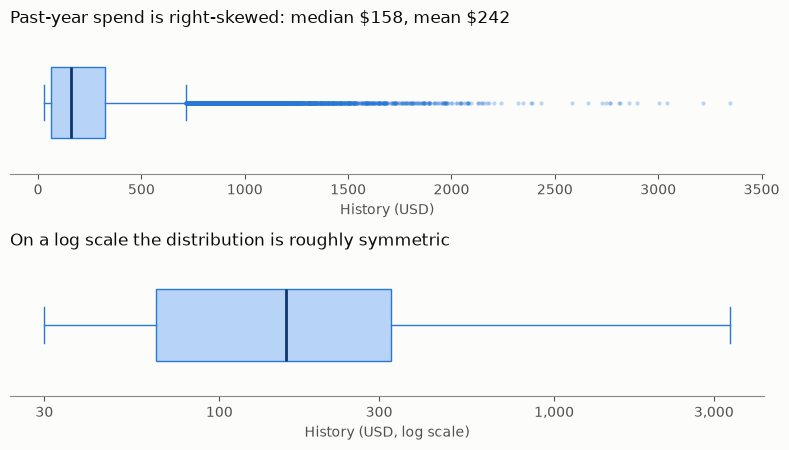

In [7]:
log_history = np.log10(df["history"])
print(f"skewness: {df['history'].skew():.2f} raw, {log_history.skew():.2f} after log transform")
print(f"customers at the minimum of ${df['history'].min():.2f}: {(df['history'] == df['history'].min()).mean():.1%}")

fig, (linear, log) = plt.subplots(2, 1, figsize=(8, 4.6))
box_plot(linear, df["history"])
linear.set_title(f"Past-year spend is right-skewed: median ${df['history'].median():,.0f}, mean ${df['history'].mean():,.0f}")
linear.set_xlabel("History (USD)")
box_plot(log, log_history)
ticks = [30, 100, 300, 1000, 3000]
log.set_xticks(np.log10(ticks), labels=[f"{tick:,}" for tick in ticks])
log.set_title("On a log scale the distribution is roughly symmetric")
log.set_xlabel("History (USD, log scale)")
plt.tight_layout()
save_and_show(fig, "history")

,customers,share
mens,,
0,28734,0.449
1,35266,0.551


,customers,share
womens,,
0,28818,0.45
1,35182,0.55


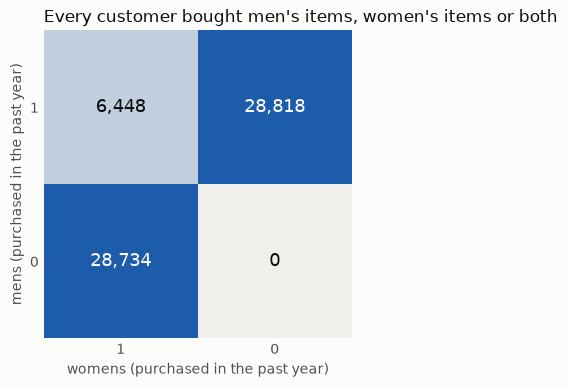

In [8]:
display(count_table("mens"))
display(count_table("womens"))

grid = pd.crosstab(df["mens"], df["womens"]).reindex(index=[1, 0], columns=[1, 0])

fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(grid.values, cmap=LinearSegmentedColormap.from_list("blue", ["#f0efec", "#1c5cab"]), vmin=0)
ax.set_xticks(range(2), labels=["1", "0"])
ax.set_yticks(range(2), labels=["1", "0"])
ax.set_xlabel("womens (purchased in the past year)")
ax.set_ylabel("mens (purchased in the past year)")
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
for row in range(2):
    for column in range(2):
        value = grid.values[row, column]
        ax.text(column, row, f"{value:,}", ha="center", va="center", fontsize=13,
                color="white" if value > grid.values.max() / 2 else INK)
ax.set_title("Every customer bought men's items, women's items or both")
save_and_show(fig, "mens_womens")

In [9]:
for column in ["zip_code", "newbie", "channel", "segment"]:
    display(count_table(column))

,customers,share
zip_code,,
Rural,9563,0.149
Surburban,28776,0.450
Urban,25661,0.401


,customers,share
newbie,,
0,31856,0.498
1,32144,0.502


,customers,share
channel,,
Multichannel,7762,0.121
Phone,28021,0.438
Web,28217,0.441


,customers,share
segment,,
Mens E-Mail,21307,0.333
No E-Mail,21306,0.333
Womens E-Mail,21387,0.334


In [10]:
repeats = df[df.duplicated()]
deduplicated = df.drop_duplicates()
print(f"repeat rows: {len(repeats):,}")
print(f"with zero spend: {(repeats['spend'] == 0).mean():.1%}")
print(f"with history at the minimum: {(repeats['history'] == df['history'].min()).mean():.1%}")
print(f"conversion: {df['conversion'].mean():.3%} all rows, {deduplicated['conversion'].mean():.3%} without repeats")
print(f"mean spend: ${df['spend'].mean():.3f} all rows, ${deduplicated['spend'].mean():.3f} without repeats")

repeat rows: 6,562
with zero spend: 100.0%
with history at the minimum: 99.5%
conversion: 0.903% all rows, 1.006% without repeats
mean spend: $1.051 all rows, $1.171 without repeats


## Outcome logic and funnel

Overall figures only, across all three experiment groups. These do not compare the groups.

In [11]:
checks = {
    "spend > 0 without conversion": ((df["spend"] > 0) & (df["conversion"] == 0)).sum(),
    "conversion without spend > 0": ((df["conversion"] == 1) & (df["spend"] == 0)).sum(),
    "conversion without visit": ((df["conversion"] == 1) & (df["visit"] == 0)).sum(),
}
for name, violations in checks.items():
    print(f"{name}: {violations}")

assert sum(checks.values()) == 0
pd.crosstab(df["visit"], df["conversion"])

spend > 0 without conversion: 0
conversion without spend > 0: 0
conversion without visit: 0


conversion,0,1
visit,,
0,54606,0
1,8816,578


spend = 0: 63,422 (99.1%)
spend > 0: 578
at the maximum of $499.00: 12
next highest value: $482.31


,spend
count,578.00
mean,116.36
std,107.87
min,29.99
25%,32.27
50%,80.80
75%,153.35
max,499.00


,buyers
spend,
29.99,136
499.00,12
362.20,2


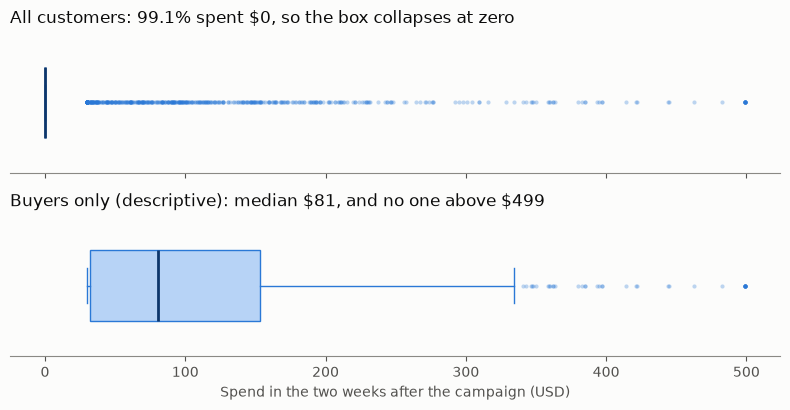

In [12]:
buyers = df.loc[df["spend"] > 0, "spend"]
print(f"spend = 0: {(df['spend'] == 0).sum():,} ({(df['spend'] == 0).mean():.1%})")
print(f"spend > 0: {len(buyers):,}")
print(f"at the maximum of ${buyers.max():,.2f}: {(buyers == buyers.max()).sum()}")
print(f"next highest value: ${buyers[buyers < buyers.max()].max():,.2f}")
display(buyers.describe().round(2).to_frame())
display(buyers.value_counts().head(3).to_frame("buyers"))

fig, (everyone, purchasers) = plt.subplots(2, 1, figsize=(8, 4.2), sharex=True)
box_plot(everyone, df["spend"])
everyone.set_title(f"All customers: {(df['spend'] == 0).mean():.1%} spent $0, so the box collapses at zero")
box_plot(purchasers, buyers)
purchasers.set_title(f"Buyers only (descriptive): median ${buyers.median():,.0f}, and no one above ${buyers.max():,.0f}")
purchasers.set_xlabel("Spend in the two weeks after the campaign (USD)")
plt.tight_layout()
save_and_show(fig, "spend")

,customers,share_of_all,share_of_previous_stage
All customers,64000,1.0000,NaN
Visited website,9394,0.1468,0.1468
Purchased,578,0.0090,0.0615


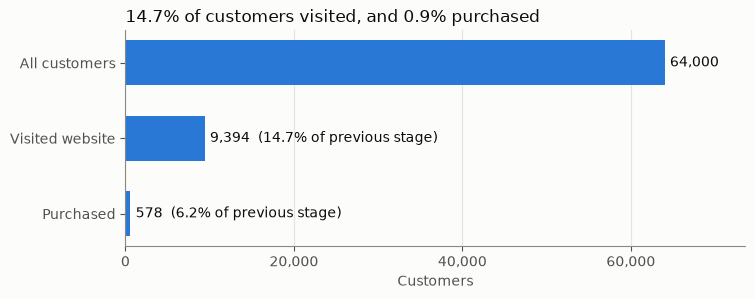

In [13]:
stages = pd.Series({
    "All customers": len(df),
    "Visited website": int(df["visit"].sum()),
    "Purchased": int(df["conversion"].sum()),
})
funnel = pd.DataFrame({
    "customers": stages,
    "share_of_all": (stages / len(df)).round(4),
    "share_of_previous_stage": (stages / stages.shift(1)).round(4),
})
display(funnel)

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(stages.index, stages.values, color=BLUE, height=0.6)
ax.invert_yaxis()
ax.set_xticks(range(0, len(df) + 1, 20000))
ax.set_xlim(0, len(df) * 1.15)
ax.set_xlabel("Customers")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for position, (stage, row) in enumerate(funnel.iterrows()):
    note = "" if position == 0 else f"  ({row['share_of_previous_stage']:.1%} of previous stage)"
    ax.text(row["customers"] + len(df) * 0.01, position, f"{row['customers']:,.0f}{note}", va="center")
ax.set_title(f"{funnel['share_of_all'].iloc[1]:.1%} of customers visited, and {funnel['share_of_all'].iloc[2]:.1%} purchased")
save_and_show(fig, "funnel")